# 第 17 章 MLflow 实验追踪

本笔记对应《机器学习课堂笔记》第 17 章，记录 MLflow 的核心概念、项目结构和实际运行结果。

学习目标：

1. 理解为什么需要实验追踪：参数、指标、模型和中间文件要可追溯、可对比、可复现；
2. 掌握 4 个手动记录 API：`log_param`、`log_metric`、`log_artifact`、`log_model`；
3. 会用父子 Run 组织批量调参；
4. 会用 `MlflowClient` 查询最优 Run、加载模型；
5. 会用 `mlflow.autolog()` 自动记录。

`mlflow_demo/` 目录下的演示脚本：

```text
knn_manual_log.py      KNN 手动记录 4 个核心 API
lr_diabetes.py         线性回归：指标、图片、CSV 报告
parent_child_run.py    父子 Run：批量搜索 KNN 的 K 值
query_best_run.py      查询最优 Run 并加载模型
autolog_logreg.py      autolog 自动记录逻辑回归
```

> MLflow 3.x 的文件型 Tracking Store 已进入维护模式。本项目使用 SQLite 元数据库 `mlflow.db`，模型和图片等制品仍保存在 `mlruns/` 目录下。


In [8]:
# %matplotlib inline

import os

# 关闭 MLflow 的首次使用提示
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

from pathlib import Path

import mlflow
from mlflow.tracking import MlflowClient
import pandas as pd
from IPython.display import Image, display

# 兼容从项目根目录、notebooks/ 或 mlflow_demo/ 目录启动
cwd = Path.cwd()
if (cwd / "mlflow_demo").exists():
    demo_dir = cwd / "mlflow_demo"
elif (cwd.parent / "mlflow_demo").exists():
    demo_dir = cwd.parent / "mlflow_demo"
else:
    demo_dir = cwd

db_path = demo_dir / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{db_path.as_posix()}")

client = MlflowClient()
EXPERIMENT_NAME = "KNN-LR实验追踪演示"
exp = client.get_experiment_by_name(EXPERIMENT_NAME)

assert exp is not None, "请先在 mlflow_demo 目录按顺序运行 5 个 MLflow 演示脚本"

print("MLflow 演示目录:", demo_dir)
print("Tracking URI:", mlflow.get_tracking_uri())
print("实验:", exp.experiment_id, exp.name)


MLflow 演示目录: c:\Users\Lenovo\Desktop\人工智能项目\机器学习\mlflow_demo
Tracking URI: sqlite:///c:/Users/Lenovo/Desktop/人工智能项目/机器学习/mlflow_demo/mlflow.db
实验: 1 KNN-LR实验追踪演示


## 17.1 为什么要学习 MLflow

机器学习项目不只是“跑一遍代码看一个分数”。一次实验至少包含：

- **参数**：学习率、K 值、正则化系数、测试集比例；
- **指标**：准确率、MSE、R²、F1、AUC；
- **制品**：混淆矩阵图片、预测 CSV、训练好的模型文件；
- **环境与版本**：Python、scikit-learn 版本，模型和数据的对应关系。

如果这些信息散落在终端输出、记事本和不同文件夹里，就会遇到“实验乱、说不清、找不回、复现不了”的问题。MLflow 把这些内容统一记录到 Run 中，并用实验（Experiment）分组，从而支持网页对比、代码查询和模型复用。

在 MLflow 中：

- **Experiment**：一组相关实验，例如 `KNN-LR实验追踪演示`；
- **Run**：一次具体训练，包含参数、指标、制品和模型；
- **Parent/Child Run**：父 Run 表示一组批量调参任务，子 Run 记录每个参数组合。


## 17.2 查看当前实验的所有 Run

下面的代码直接查询本地 `mlflow_demo/mlflow.db` 与 `mlruns/`，不会重新训练模型。


In [9]:
runs = client.search_runs(
    experiment_ids=[exp.experiment_id],
    order_by=["attributes.start_time ASC"],
    max_results=100,
)

rows = []
for r in runs:
    params = {
        k: v
        for k, v in r.data.params.items()
        if k in ("n_neighbors", "test_size", "C")
    }
    metrics = {
        k: v
        for k, v in r.data.metrics.items()
        if k in (
            "accuracy",
            "mse",
            "r2",
            "training_accuracy_score",
            "training_f1_score",
            "training_roc_auc",
        )
    }
    rows.append({
        "Run 名称": r.info.run_name,
        "run_id": r.info.run_id,
        "父 Run": r.data.tags.get("mlflow.parentRunId", ""),
        "参数": ", ".join(f"{k}={v}" for k, v in params.items()),
        "关键指标": ", ".join(f"{k}={v:.4f}" for k, v in metrics.items()),
        "状态": r.info.status,
    })

runs_df = pd.DataFrame(rows)
runs_df


,Run 名称,run_id,父 Run,参数,关键指标,状态
0,KNN第一次手动记录run,90c58265dd63431bbab0d8e2270e2acf,,n_neighbors=5,accuracy=1.0000,FINISHED
1,线性回归：业务指标与报告（糖尿病数据集）,59748789e4e44707b777bd1f377d80e4,,test_size=0.2,"mse=2900.1936, r2=0.4526",FINISHED
2,【父run】KNN批量搜索K值,49970b71671f469d9b83d176f7917fcb,,,,FINISHED
3,子run K=1,824756fcccb44b24aa8635c4e561fd90,49970b71671f469d9b83d176f7917fcb,n_neighbors=1,accuracy=1.0000,FINISHED
4,子run K=3,376506bece6541b5ab2a82a4dc78974a,49970b71671f469d9b83d176f7917fcb,n_neighbors=3,accuracy=1.0000,FINISHED
5,子run K=5,648bd18895e04877ac564f31663c5624,49970b71671f469d9b83d176f7917fcb,n_neighbors=5,accuracy=1.0000,FINISHED
6,子run K=7,bf358e6c2faf42e4a90d17ee7cd9a728,49970b71671f469d9b83d176f7917fcb,n_neighbors=7,accuracy=0.9667,FINISHED
7,autolog自动记录_逻辑回归,d5245c09ffe740419b216dc5162ca96b,,C=1.0,"training_f1_score=0.9750, training_accuracy_sc...",FINISHED


## 17.2.5 KNN：手动记录 4 个核心 API

`knn_manual_log.py` 用鸢尾花数据集训练 KNN，并手动调用：

```python
mlflow.log_param("n_neighbors", k)               # 超参数
mlflow.log_metric("accuracy", acc)               # 指标
mlflow.log_artifact(img_path)                    # 图片等文件
mlflow.sklearn.log_model(knn_model, name="knn_model")  # 模型
```

`with mlflow.start_run(...)` 会把这一组记录绑定到同一次 Run。


run_id: 90c58265dd63431bbab0d8e2270e2acf
参数: {'n_neighbors': '5'}
指标: {'accuracy': 1.0}
制品: ['knn_conf_matrix.png']


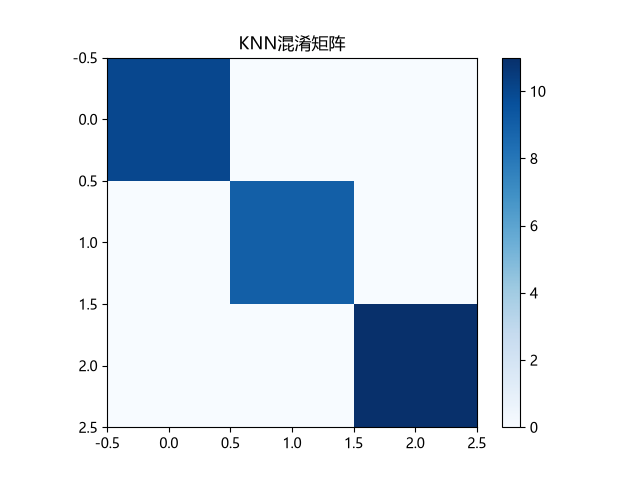

已记录模型: [('m-06b8b03c7ec14b849aafb6d7deb09ad2', 'knn_model')]


In [10]:
manual = next(r for r in runs if r.info.run_name == "KNN第一次手动记录run")

print("run_id:", manual.info.run_id)
print("参数:", manual.data.params)
print("指标:", {k: round(v, 4) for k, v in manual.data.metrics.items()})
print("制品:", [a.path for a in client.list_artifacts(manual.info.run_id)])

img_path = client.download_artifacts(manual.info.run_id, "knn_conf_matrix.png")
display(Image(filename=img_path, width=420))

try:
    models = client.search_logged_models(
        experiment_ids=[exp.experiment_id],
        filter_string=f"source_run_id='{manual.info.run_id}'",
    )
    print("已记录模型:", [(m.model_id, m.name) for m in models])
except Exception as e:
    print("模型查询跳过:", e)


**注意**：Iris 是入门数据集，KNN 在 54 条测试样本上很容易得到 1.0；这里的重点是把参数、指标、图片和模型完整记录下来，而不是用这个分数评价模型好坏。

MLflow 3.x 把模型放在独立的 **Models** 区域（Logged Models），不一定出现在 Run 的普通 Artifacts 列表中；但 `runs:/<run_id>/knn_model` 仍然可以加载。


## 17.2.6 线性回归：指标、图片与 CSV 报告

`lr_diabetes.py` 在糖尿病数据集上训练线性回归，记录：

- 参数 `test_size=0.2`；
- 指标 `mse`、`r2`、自定义业务指标 `avg_relative_error`；
- 真实值 vs 预测值散点图；
- 预测结果 CSV；
- 线性回归模型。


run_id: 59748789e4e44707b777bd1f377d80e4
参数: {'test_size': '0.2'}
指标: {'mse': 2900.1936, 'r2': 0.4526, 'avg_relative_error': 0.35}
制品: ['lr_pred_compare.png', 'lr_predict_report.csv']


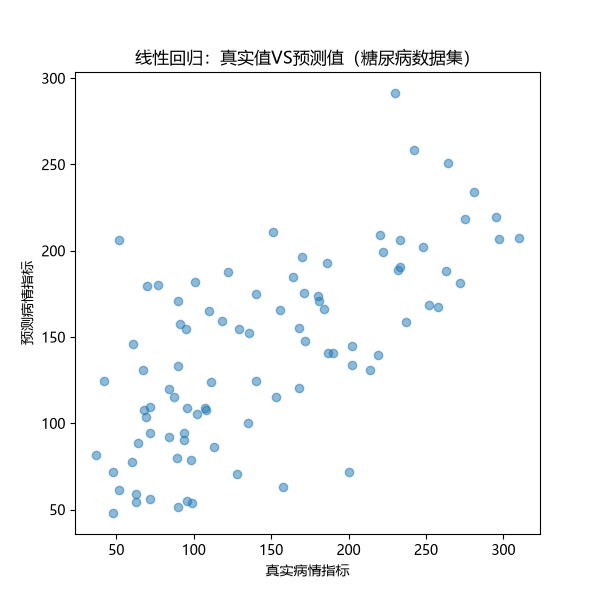

,true_value,pred_value
0,219.0,139.547558
1,70.0,179.517208
2,202.0,134.038756
3,230.0,291.417029
4,111.0,123.789659


In [11]:
linear = next(r for r in runs if r.info.run_name.startswith("线性回归"))

print("run_id:", linear.info.run_id)
print("参数:", linear.data.params)
print("指标:", {k: round(v, 4) for k, v in linear.data.metrics.items()})
print("制品:", [a.path for a in client.list_artifacts(linear.info.run_id)])

img_path = client.download_artifacts(linear.info.run_id, "lr_pred_compare.png")
display(Image(filename=img_path, width=420))

csv_path = client.download_artifacts(linear.info.run_id, "lr_predict_report.csv")
display(pd.read_csv(csv_path).head())


## 17.2.7 父子 Run：批量搜索 KNN 的 K 值

`parent_child_run.py` 先开启父 Run，再对 `K=1,3,5,7` 分别开一个 `nested=True` 的子 Run。网页中四个子 Run 会折叠挂在父 Run 下面，适合比较一组超参数。


In [12]:
parent = next(r for r in runs if r.info.run_name.startswith("【父run】"))
children = [
    r for r in runs
    if r.data.tags.get("mlflow.parentRunId") == parent.info.run_id
]

child_rows = []
for r in children:
    child_rows.append({
        "子 Run": r.info.run_name,
        "K": r.data.params.get("n_neighbors"),
        "准确率": round(r.data.metrics.get("accuracy", float("nan")), 4),
        "run_id": r.info.run_id,
    })

print("父 Run:", parent.info.run_name, parent.info.run_id)
pd.DataFrame(child_rows)


父 Run: 【父run】KNN批量搜索K值 49970b71671f469d9b83d176f7917fcb


,子 Run,K,准确率,run_id
0,子run K=1,1,1.0000,824756fcccb44b24aa8635c4e561fd90
1,子run K=3,3,1.0000,376506bece6541b5ab2a82a4dc78974a
2,子run K=5,5,1.0000,648bd18895e04877ac564f31663c5624
3,子run K=7,7,0.9667,bf358e6c2faf42e4a90d17ee7cd9a728


## 17.2.7 用代码查询最优 Run 并加载模型

`query_best_run.py` 使用 `MlflowClient.search_runs`：

```python
runs = client.search_runs(
    [exp_id],
    order_by=["metrics.accuracy DESC"],
)
best_run = runs[0]
model = mlflow.sklearn.load_model(
    f"runs:/{best_run.info.run_id}/knn_model"
)
```

这比手动翻网页更适合自动化和批量评估。


In [13]:
best_runs = client.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string="metrics.accuracy >= 0",
    order_by=["metrics.accuracy DESC"],
    max_results=1,
)
best = best_runs[0]

print("最优 KNN Run:", best.info.run_name)
print("run_id:", best.info.run_id)
print("参数:", best.data.params)
print("准确率:", round(best.data.metrics["accuracy"], 4))

best_model = mlflow.sklearn.load_model(
    f"runs:/{best.info.run_id}/knn_model"
)

from sklearn.datasets import load_iris
X, y = load_iris(return_X_y=True)
print("前 5 个样本的预测:", best_model.predict(X[:5]))


最优 KNN Run: 子run K=5
run_id: 648bd18895e04877ac564f31663c5624
参数: {'n_neighbors': '5'}
准确率: 1.0
前 5 个样本的预测: [0 0 0 0 0]


## 17.2.8 autolog：一行代码自动记录

`autolog_logreg.py` 先调用 `mlflow.autolog()`，再正常训练逻辑回归。MLflow 会自动抓取：

- 构造参数：`C`、`max_iter`、`solver` 等；
- 训练指标：准确率、精确率、召回率、F1、log loss、ROC AUC；
- 混淆矩阵图片；
- 训练好的模型。


run_id: d5245c09ffe740419b216dc5162ca96b
关键参数: {'C': '1.0', 'max_iter': '200', 'solver': 'lbfgs'}
训练指标: {'training_precision_score': 0.9768, 'training_recall_score': 0.975, 'training_f1_score': 0.975, 'training_accuracy_score': 0.975, 'training_log_loss': 0.1356, 'training_roc_auc': 0.9981, 'training_score': 0.975}
制品: ['estimator.html', 'training_confusion_matrix.png']


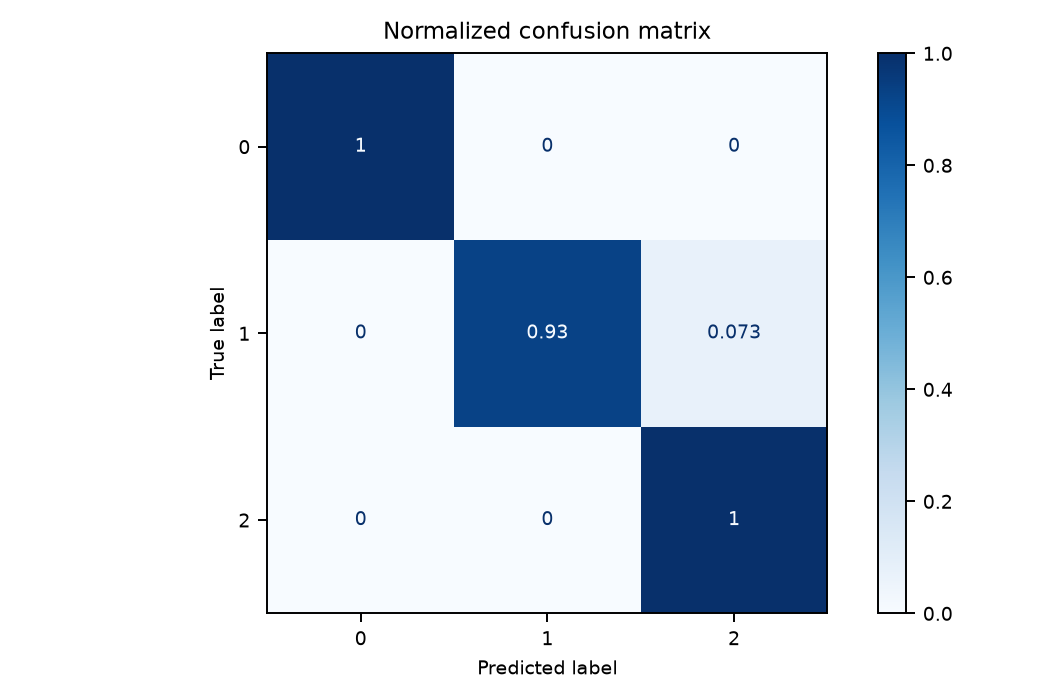

已记录模型: [('m-e5b12f65b6694b7bbc25dc2795e63a65', 'model')]


In [14]:
auto = next(r for r in runs if r.info.run_name == "autolog自动记录_逻辑回归")

print("run_id:", auto.info.run_id)
print("关键参数:", {
    k: auto.data.params.get(k)
    for k in ("C", "max_iter", "solver")
})
print("训练指标:", {
    k: round(v, 4) for k, v in auto.data.metrics.items()
})
print("制品:", [a.path for a in client.list_artifacts(auto.info.run_id)])

img_path = client.download_artifacts(
    auto.info.run_id, "training_confusion_matrix.png"
)
display(Image(filename=img_path, width=420))

try:
    models = client.search_logged_models(
        experiment_ids=[exp.experiment_id],
        filter_string=f"source_run_id='{auto.info.run_id}'",
    )
    print("已记录模型:", [(m.model_id, m.name) for m in models])
except Exception as e:
    print("模型查询跳过:", e)


## 17.3 运行顺序与网页查看

进入 `mlflow_demo` 目录执行。Windows cmd 下先设置环境变量：

```bat
set PYTHONUTF8=1
set MLFLOW_TRACKING_URI=sqlite:///mlflow.db
```

PowerShell 使用：

```powershell
$env:PYTHONUTF8="1"
$env:MLFLOW_TRACKING_URI="sqlite:///mlflow.db"
```

然后按顺序运行：

```bash
python knn_manual_log.py
python lr_diabetes.py
python parent_child_run.py
python query_best_run.py
python autolog_logreg.py
```

启动网页：

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

浏览器访问 <http://127.0.0.1:5000>。在实验 `KNN-LR实验追踪演示` 中可以对比：

| 实验 | 关键结果 |
|---|---|
| KNN 手动记录（K=5） | 准确率 1.0000，记录混淆矩阵和模型 |
| 线性回归（糖尿病） | R²=0.4526，MSE=2900.1936，记录散点图和 CSV |
| 父 Run / 子 Run | K=1、3、5 准确率 1.0000；K=7 准确率 0.9667 |
| autolog 逻辑回归 | 训练准确率 0.9750，F1=0.9750，ROC AUC=0.9981 |
| 最优 Run 查询 | 按 accuracy 排序取第一名，加载 `knn_model` 并预测 |

## 小结

- `log_param`、`log_metric`、`log_artifact`、`log_model` 是最常用的 4 个手动记录 API；
- 父 Run 用来组织一组调参实验，子 Run 记录每个参数组合；
- `mlflow.autolog()` 可以自动记录 scikit-learn 的参数、指标、混淆矩阵和模型；
- 实验记录的价值在于**可追溯、可对比、可复现**，而不是单纯追求一个高分；
- 在 Windows 下运行含中文注释的 autolog 脚本时，先用 `PYTHONUTF8=1` 开启 UTF-8 模式，避免 GBK 解码警告。
